Lien du notebook : https://colab.research.google.com/drive/1EZ6C3ANFemILW4_i8lKk4L-c2AZMSQwo?usp=sharing

Récupération des débats dans un csv depuis Kialo qui est placé dans le dossier kialo_exports

In [1]:
# pip install -r requirements.txt

In [2]:

import os
import re
import time
import getpass
from enum import Enum

import requests
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.chrome.options import Options
import google_colab_selenium as gs

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier


In [3]:
class KialoSort(Enum):
    RANK_ACTIVITY = "rank_and_latest_activity"
    VIEW = "view_count" # on récupère le nombre de vues pour le filtre
    LAST_ACTIVITY = "latest_activity"

class KialoFilter(Enum):
    PROMOTED = "promoted"
    PARTICIPATE = "participate"
    LAST_ACTIVITY = "latest_activity"
    TAG = "tag" # les tags vont nous servir pour trier PRO et CON
    TAG_ALL = "tag_all"

class KialoTool:
    def getTags(self):
        tags = requests.get("https://www.kialo.com/api/v1/discussiontags")
        return [item['tagName'] for item in tags.json()["tags"]] #chaque tags de débats

    def getDiscussions(self, filter: KialoFilter, sort: KialoSort, limit=250):
        req = f"https://www.kialo.com/api/v1/discussions?filter={filter.value}&sort={sort.value}&limit={limit}&skip=0" #slug filtrer à chaque itération
        response = requests.get(req)
        response.raise_for_status()
        return response.json()["discussions"]

    def processDiscussions(self, discussions, export=False):
        idsUrl = [x["title"].lower().replace("?", "").replace(" ", "-") + "-" + str(x["id"]) for x in discussions]
        titles = [x["title"] for x in discussions]
        ids = [x["id"] for x in discussions]
        tags = [", ".join(x.get("tags", [])) if isinstance(x.get("tags"), list) else str(x.get("tags", "")) for x in discussions]
        df_data = {
            "id": ids,
            "title": titles,
            "kialoUrlId": idsUrl,
            "tags": tags}
        df = pd.DataFrame.from_dict(df_data)
        if export:
            os.makedirs("kialo_exports", exist_ok=True) # on vérifie que le dossier existe bien
            df.to_csv("kialo_exports/kialo-top250-discussions.csv", index=False)

        return df

k = KialoTool()
raw_discussions = k.getDiscussions(filter=KialoFilter.PROMOTED, sort=KialoSort.RANK_ACTIVITY, limit=250)
df_discussions = k.processDiscussions(raw_discussions, export=True)

print("Successfully fetched and processed " + str(len(df_discussions)) + " discussions.")
print(df_discussions.head())

Successfully fetched and processed 250 discussions.
      id                                              title  \
0  29355                        Are Purity Pledges Harmful?   
1  10143                Should American Football Be Banned?   
2  30339                   Should there be One World State?   
3  31027  Do fair trade products cause more good than harm?   
4  64072  Should failing banks receive bailouts from the...   

                                          kialoUrlId  \
0                   are-purity-pledges-harmful-29355   
1           should-american-football-be-banned-10143   
2              should-there-be-one-world-state-30339   
3  do-fair-trade-products-cause-more-good-than-ha...   
4  should-failing-banks-receive-bailouts-from-the...   

                                                tags  
0            Purity, Sex, Virginity, Feminism, Women  
1  Sports, USA, Football, American_Football, Ente...  
2      States, Nations, Culture, Economics, Politics  
3          T

à partir des csv récupération de chaque débats individuellement dans le dossier kialo_export/debates

In [4]:
class KialoSort(Enum):
    RANK_ACTIVITY = "rank_and_latest_activity"
    VIEW          = "view_count"
    LAST_ACTIVITY = "latest_activity"
class KialoFilter(Enum):
    PROMOTED      = "promoted"
    PARTICIPATE   = "participate"
    LAST_ACTIVITY = "latest_activity"
    TAG           = "tag"
    TAG_ALL       = "tag_all"
class KialoTool:
    def getDiscussions(self, filter: KialoFilter, sort: KialoSort, limit=250):
        url = "https://www.kialo.com/api/v1/discussions?filter=" + str(filter.value) + "&sort=" + str(sort.value) + "&limit=" + str(limit) + "&skip=0"
        reponse = requests.get(url, timeout=30)
        reponse.raise_for_status()
        donnees = reponse.json()
        return donnees["discussions"]

    def discussions2urlID(self, discussions, export=True):
        idsUrl = []
        tags = []
        for item in discussions:
            titre = item["title"].lower().replace("?", "").replace(" ", "-")
            identifiant = str(item["id"])
            idsUrl.append(titre + "-" + identifiant)
            if "tags" in item:
                tags.append(item["tags"])
            else:
                tags.append([])
        if export:
            if not os.path.exists("kialo_exports"):
                os.makedirs("kialo_exports")
            # data frame panda pour transférer vers csv
            tableau = pd.DataFrame({"kialoUrlId": idsUrl, "tags": tags})
            tableau.to_csv("kialo_exports/kialo-url-ids.csv", index=False)
        return idsUrl

kialoUsername = getpass.getpass("Email/identifiant Kialo : ")
secret = getpass.getpass("mdp Kialo : ")
outil = KialoTool()
print("Récupération débats.")
discussions_list = outil.getDiscussions(
    filter=KialoFilter.TAG,
    sort=KialoSort.RANK_ACTIVITY,
    limit=250) # on prend les 250 meilleurs
url_ids = outil.discussions2urlID(discussions_list, export=True)

def downloadDiscussions(disscusionUrlIds, username, password):
    save_path = os.path.abspath("kialo_exports/debates")
    if not os.path.exists(save_path):
        os.makedirs(save_path)

    options = Options()
    options.add_experimental_option("prefs", {
        "download.default_directory": save_path,
        "download.prompt_for_download": False,
        "directory_upgrade": True
    })

    print("\n Initialisation navigateur Google Colab")
    driver = gs.Chrome(options=options)

    try:
        print("Connexion à Kialo.")
        driver.get("https://www.kialo.com/login")
        time.sleep(3) # attente de 3 secondes le temps que ça charge

        # pour se connecter
        id_field = driver.find_element(By.ID, "emailOrUsername")
        password_field = driver.find_element(By.ID, "password")
        loginButton = driver.find_element(By.CLASS_NAME, "login-form__submit")
        id_field.send_keys(username)
        password_field.send_keys(password)
        loginButton.click()

        WebDriverWait(driver, 15).until(
            EC.presence_of_element_located((By.CLASS_NAME, 'home-page-section__header'))
        )
        print("Téléchargement débats")
        for urlId in tqdm(disscusionUrlIds):
            lien = "https://www.kialo.com/export/" + str(urlId) + ".txt"
            driver.get(lien)
            time.sleep(1.2)

    except Exception as e:
        print("\n Erreur : " + str(e))
    finally:
        driver.quit()

        fichiers_telecharges = []
        for f in os.listdir(save_path):
            if f.endswith(".txt"):
                fichiers_telecharges.append(f)

        print("\n " + str(len(fichiers_telecharges)) + ".txt dans " + str(save_path))
downloadDiscussions(url_ids, kialoUsername, secret)

Email/identifiant Kialo : ··········
mdp Kialo : ··········
Récupération débats.

 Initialisation navigateur Google Colab


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Connexion à Kialo.
Téléchargement débats


100%|██████████| 250/250 [06:42<00:00,  1.61s/it]


 246.txt dans /content/kialo_exports/debates


Classification et training parmis plusieurs modèles + TD-IDF et régression linéaire ainsi que baseline de comparaison

In [5]:
class KialoParser:
    def __init__(self):
        self.exports_dir = "kialo_exports/debates" # dossier cible à analyser
        if not os.path.exists(self.exports_dir):
            if os.path.exists("kialo_exports"):
                self.exports_dir = "kialo_exports"

    def load_debates(self):
        dossier_existe = os.path.exists(self.exports_dir)
        if dossier_existe == False: # si le dossier n'existe pas on retourne rien
            return []
        else:
            files_list = os.listdir(self.exports_dir)
            fichiers_txt = []
            for nom_f in files_list:
                if nom_f.endswith('.txt'): #si le fichier est en txt c'est un débat à analyser
                    fichiers_txt.append(nom_f)

            liste_debats = [] # initialisation liste débat vide
            for fichier_actuel in fichiers_txt: # pour chaque fichier
                chemin_complet = os.path.join(self.exports_dir, fichier_actuel) # chemin dans le répertoire du fichier
                paires_pos, liste_claims = self.parse_file(chemin_complet) # chaque paire parent/enfant et liste affirmations unique du débat

                if len(paires_pos) > 0: # si il existe des paires parent/enfant
                    if len(liste_claims) > 1:
                        mon_debat = {
                            "debate_id": fichier_actuel, # chaque débat attribuer par fichier
                            "pos_pairs": paires_pos, # paire
                            "claims": liste_claims
                        }
                        liste_debats.append(mon_debat) # alors on ajoute a la liste de débat

            return liste_debats

    def parse_file(self, file_path):
        pairs, texts, items = [], [], []
        try:
            rows = open(file_path, 'r', encoding='utf-8', errors='ignore').readlines()
        except:
            return pairs, texts

        for row in rows:
            low = row.strip().lower()
            pro = any(w in low for w in ["pro", "support", "favor"]) # on tri argument pro selon tag des débat
            con = any(w in low for w in ["contra", "con", "against", "refute"]) # pareil on tri con
            cleaning = re.sub(r'^[\d\.\-\*\s]*(pro|contra|support|con|against|refute):?\s*', '', row.strip(), flags=re.IGNORECASE).strip() # le texte est nettoyé pour ne pas avoir autre chose
            if (pro or con) and cleaning:
                texts.append(cleaning)
                items.append((cleaning, len(row) - len(row.lstrip()), pro))

        for i, (name, space, pro) in enumerate(items):
            for j in range(i - 1, -1, -1): # on regarde l'argument parent de l'argument actuel
                if items[j][1] < space: # le parent possède forcément moins d'indentation que l'enfant
                    if name != items[j][0]: # si il n'ont pas le même texte (évite bouclage)
                        pairs.append({"child": name, "parent": items[j][0], "label_class": int(pro)}) # on ajoute la paire parent/enfant
                    break # le break sert à faire en sorte que les enfants aient les bons grand-parent (pourrait être rattaché à plusieurs grand-parents)
        return pairs, list(set(texts))


if __name__ == "__main__":
    parser = KialoParser()
    debates_data = parser.load_debates()
    task1_rows = []
    for debate in debates_data:
        for p in debate["pos_pairs"]:
            row = {
                "premise": p["child"], # graphe de connexion TF-IDF parent enfant labelisé
                "conclusion": p["parent"], # conclusion de l'argument toujours parent
                "label": p["label_class"]
            }
            task1_rows.append(row)

    df_task1 = pd.DataFrame(task1_rows)
    print("\n Nb total de paires : " + str(len(df_task1)))

    df_task1["text_pair"] = df_task1["premise"] + " | " + df_task1["conclusion"]
    data_training_x, data_testing_x, data_training_y, data_testing_y = train_test_split(
        df_task1["text_pair"],
        df_task1["label"],
        test_size=0.4,
        random_state=43 # choix de seed aléatoire
    )

    results = []
    dummy = DummyClassifier(strategy="most_frequent") # classification de la basline (seulement prendre sans corrélation entre débats)
    dummy.fit(data_training_x, data_training_y)
    dummy_preds = dummy.predict(data_testing_x)
    baseline_acc = accuracy_score(data_testing_y, dummy_preds) # calcul accuracy baseline
    results.append({"Modèle": "Baseline", "Accuracy": baseline_acc})
    print("\n" + "~" * 40)
    print(" ENTRAÎNEMENT MODÈLES ")
    print("~" * 40)
    vectorizer = TfidfVectorizer(max_features=5000) # nombre de features limité a 5000 pour ne pas avoir d'overfitting
    data_training_vec = vectorizer.fit_transform(data_training_x)
    data_testing_vec = vectorizer.transform(data_testing_x)

    models_list = [
        ("Linear SVM", LinearSVC(random_state=43, max_iter=5000)),("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42)),
        ("MLP", MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=20, random_state=42))]
        #choix des modèles car ils sont pertinent dans un domaine linéaire comme le notre

    for name, model in models_list:
        model.fit(data_training_vec, data_training_y)
        predictions = model.predict(data_testing_vec)
        acc = accuracy_score(data_testing_y, predictions)
        results.append({"Modèle": name, "Accuracy": acc})
        print(name + " : " + str(round(acc * 100, 2)) + "%")

    df_res = pd.DataFrame(results)
    df_res = df_res.sort_values(by="Accuracy", ascending=False)

    print("\n" + "~" * 40)
    print(" CLASSEMENT MODÈLES ")
    print("~" * 40)
    print(df_res.to_string(index=False))
    print("~" * 40)


 Nb total de paires : 38067

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 ENTRAÎNEMENT MODÈLES 
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Linear SVM : 77.48%
Logistic Regression : 76.61%
MLP : 76.16%

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
 CLASSEMENT MODÈLES 
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
             Modèle  Accuracy
         Linear SVM  0.774808
Logistic Regression  0.766139
                MLP  0.761608
           Baseline  0.552834
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


Linear SVM accuracy avec différents nombre de features :

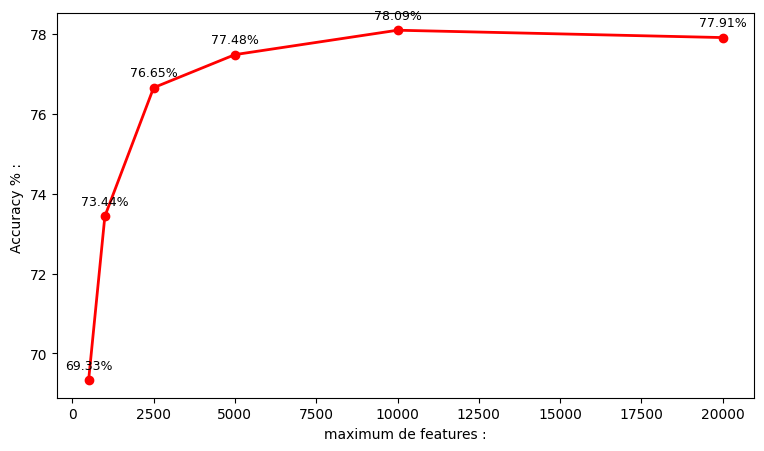

In [10]:
if 'data_training_x' in globals():
        if 'data_testing_y' in globals():
            f = [500, 1000, 2500, 5000, 10000, 20000]
            res = []

            for i in f:
                vec = TfidfVectorizer(max_features=i) # création vecteurs TF-IDF pour matrice vectorielle
                tr = vec.fit_transform(data_training_x) # apprentissage des mots sur le modèle
                te = vec.transform(data_testing_x) # applique vocabulaire aux mots du texte
                m = LinearSVC(random_state=43, max_iter=5000) # prédictions SVM
                m.fit(tr, data_training_y)
                p = m.predict(te)
                res.append(accuracy_score(data_testing_y, p) * 100)
            plt.figure(figsize=(9, 5))
            plt.plot(f, res, marker='o', color='red', linewidth=2)
            for x, y in zip(f, res):
                plt.text(x, y + 0.2, f"{y:.2f}%", ha='center', va='bottom', fontsize=9)

            plt.ylabel("Accuracy % : ")
            plt.xlabel("maximum de features :")
            plt.show()

MLP et régression logistique avec différents nombre de features :

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py

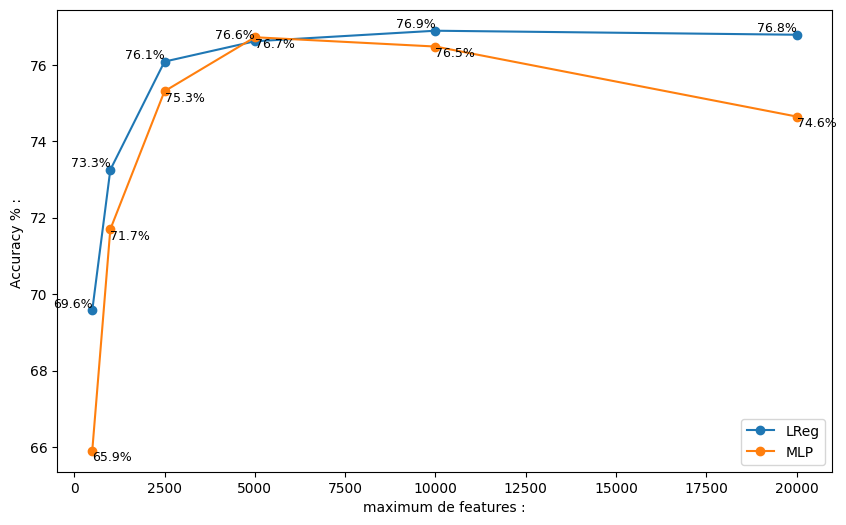

In [9]:
if 'data_training_x' in globals():
        if 'data_testing_x' in globals():
            f = [500, 1000, 2500, 5000, 10000, 20000]
            mod1 = LogisticRegression(max_iter=1000, random_state=43)
            mod2 = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=20, random_state=43) # couche neurones 128 à 64 avec seed à 43
            plt.figure(figsize=(10, 6))
            res1 = []
            for i in f:
                vec = TfidfVectorizer(max_features=i) # création vecteurs TF-IDF pour matrice vectorielle
                tr = vec.fit_transform(data_training_x)# apprentissage des mots sur modèle de régression linéaire
                te = vec.transform(data_testing_x)
                mod1.fit(tr, data_training_y)
                pr = mod1.predict(te)
                res1.append(accuracy_score(data_testing_y, pr) * 100) # score accuracy de regression lineaire

            plt.plot(f, res1, marker='o', label="LReg")
            for xi, yi in zip(f, res1):
                plt.text(xi, yi, f"{yi:.1f}%", fontsize=9, ha='right', va='bottom')

            res2 = []
            for j in f:
                vec = TfidfVectorizer(max_features=j) # création vecteurs TF-IDF pour matrice vectorielle
                tr = vec.fit_transform(data_training_x) # apprentissage des mots sur modèle
                te = vec.transform(data_testing_x) # applique vocabulaire aux mots du texte
                mod2.fit(tr, data_training_y) # MLP tente de prédire pour voir si il trouve qui est pro ou con parmis les paires
                pr = mod2.predict(te)
                res2.append(accuracy_score(data_testing_y, pr) * 100) # comparaison prédiction avec réalité (vrai/vrai ou vrai/faux etc...)

            plt.plot(f, res2, marker='o', label="MLP")

            for xi, yi in zip(f, res2):
                plt.text(xi, yi, f"{yi:.1f}%", fontsize=9, ha='left', va='top')

            plt.ylabel("Accuracy % : ")
            plt.xlabel("maximum de features :")
            plt.legend()
            plt.show()